In [1]:
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from platy5p1.metrics import accuracy, assign_mean
import seaborn as sns

## Evaluate matching

Matching is a list of pairs of correcponding objects. For simplicity the labels are the indices of points in fixed and moving point clouds, not the segmentation mask IDs

## Read fixed point cloud

EM sample was used as a template to match all other samples

In [2]:
data_dir = Path("../data")
fixed_pcd_df = pd.read_csv(data_dir / "em.csv")

In [3]:
fixed_pcd_df.head()

,label,z,y,x,mean_stmhc,reg_gt,reg_gt_reflected
0,1,469.772377,219.499310,799.116611,0.0,-1,-1
1,2,365.899285,321.521310,981.375170,0.0,-1,-1
2,3,424.458640,268.998526,993.971721,0.0,-1,-1
3,4,405.234623,301.805524,856.752048,0.0,-1,-1
4,5,405.384524,339.028451,656.206050,0.0,-1,-1


## Calculate metrics for each of the confocal samples

In [4]:
def plot_muscle_signal(fixed_pcd_df, moving_pcd_df, assigned_mean_stmhc):
    fig, axs = plt.subplots(1, 3, figsize=(15, 8), sharey="row")

    ax= axs[0]
    ax.scatter(fixed_pcd_df["x"], fixed_pcd_df["y"], c=fixed_pcd_df["mean_stmhc"], alpha=0.5, s=12)
    ax.set_title("EM muscle segmentation", va='top')
    ax.set_aspect("equal")

    ax= axs[1]
    ax.scatter(moving_pcd_df["x"], moving_pcd_df["y"], c=moving_pcd_df["mean_stmhc"], alpha=0.5, s=12)
    ax.set_title("StMhc staining in confocal", va='top')
    ax.set_aspect("equal")

    ax= axs[2]
    ax.scatter(fixed_pcd_df["x"], fixed_pcd_df["y"], c=assigned_mean_stmhc["mean_stmhc"], alpha=0.5, s=12)
    ax.set_title("StMhc staining transferred to EM", va='top')
    ax.set_aspect("equal")

    plt.show()

Platy 1 vs EM accuracy: 0.196


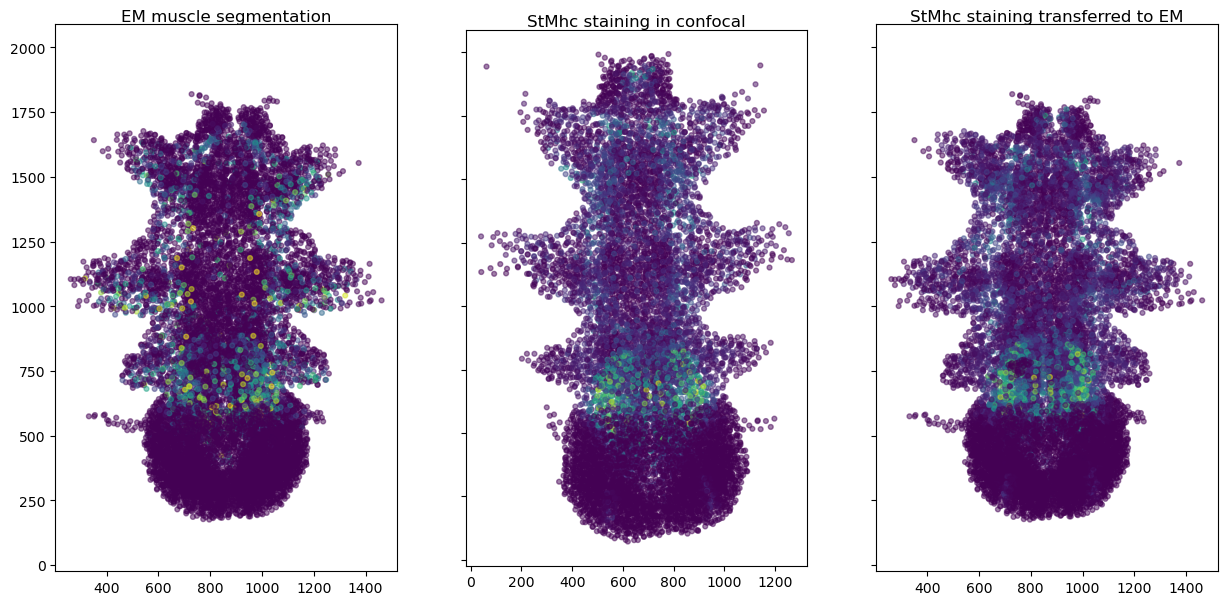

Platy 2 vs EM accuracy: 0.164


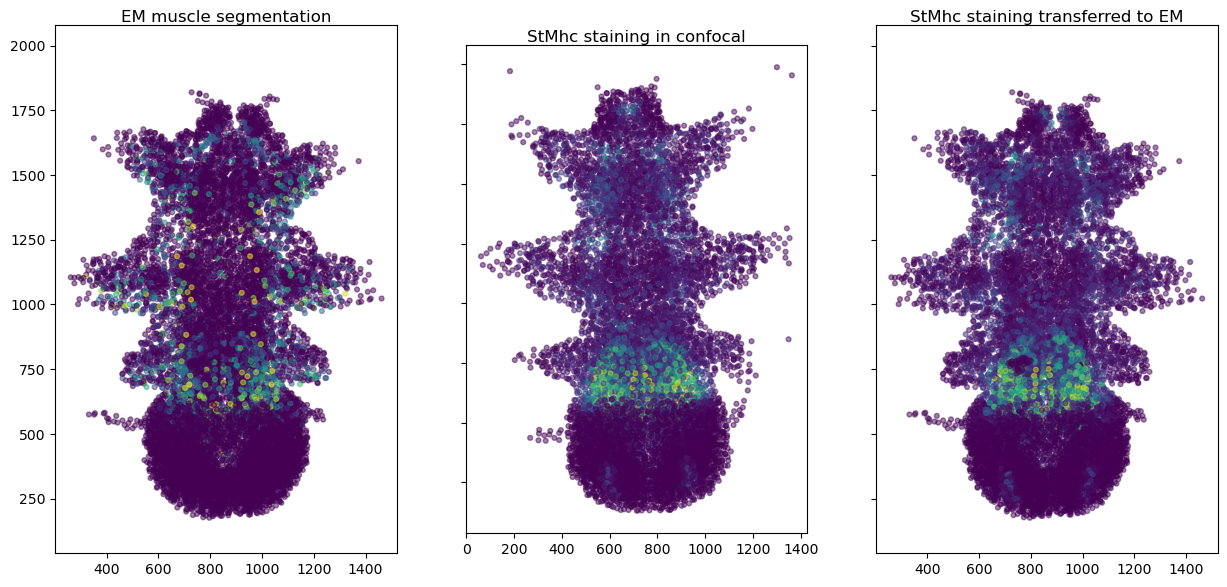

Platy 3 vs EM accuracy: 0.204


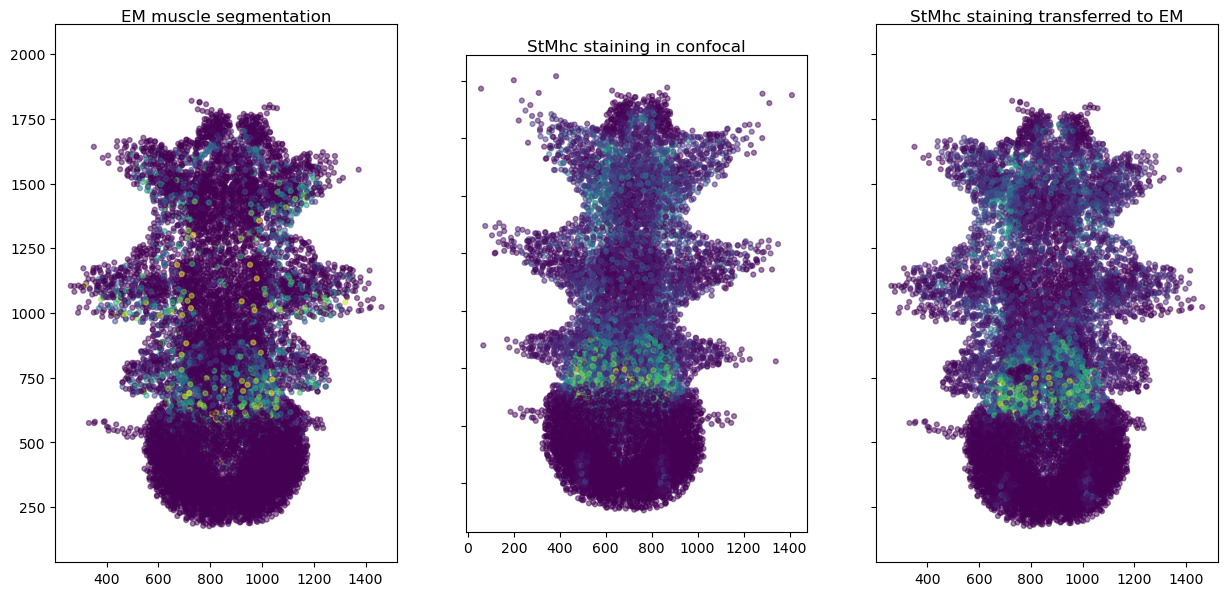

Platy 4 vs EM accuracy: 0.204


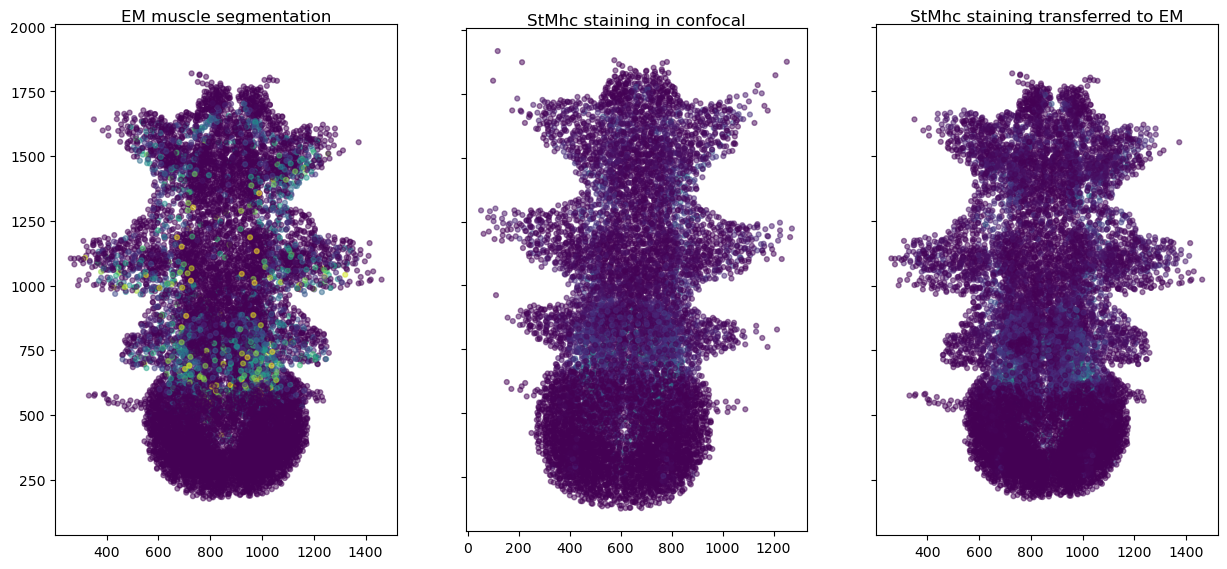

Platy 5 vs EM accuracy: 0.143


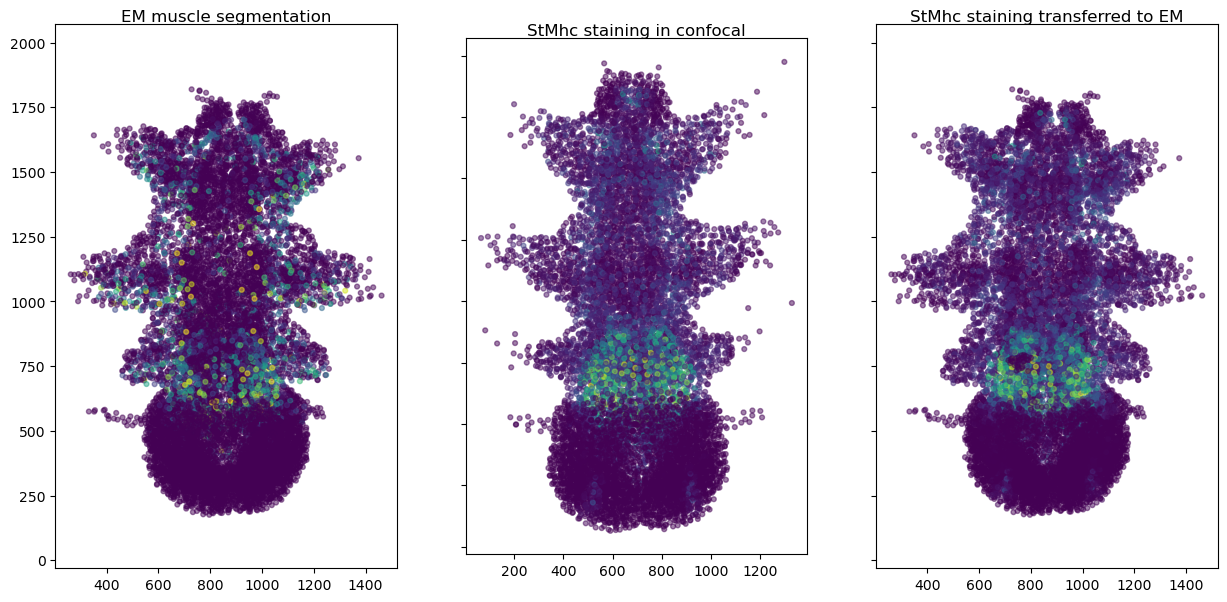

In [5]:
muscle_signal = pd.DataFrame()
muscle_signal["em"] = fixed_pcd_df["mean_stmhc"]

for i in range(1, 6):
    moving_pcd_df = pd.read_csv(data_dir / f"stmhc_pl{i}.csv")
    matching_pairs = np.genfromtxt(f"matching/matched_pairs_pl{i}.txt", delimiter=",").astype(int)
    assigned_mean_stmhc = assign_mean("mean_stmhc", fixed_pcd_df, moving_pcd_df, matching_pairs)
    acc = accuracy(fixed_pcd_df["reg_gt"].to_numpy(), moving_pcd_df["reg_gt"].to_numpy(), matching_pairs[:, 0], matching_pairs[:, 1])
    print(f"Platy {i} vs EM accuracy: {acc:.3f}")
    muscle_signal[f"pl{i}"] = assigned_mean_stmhc["mean_stmhc"]

    plot_muscle_signal(fixed_pcd_df, moving_pcd_df, assigned_mean_stmhc)

Text(0.5, 1.0, 'Correlation of transferred muscle signals')

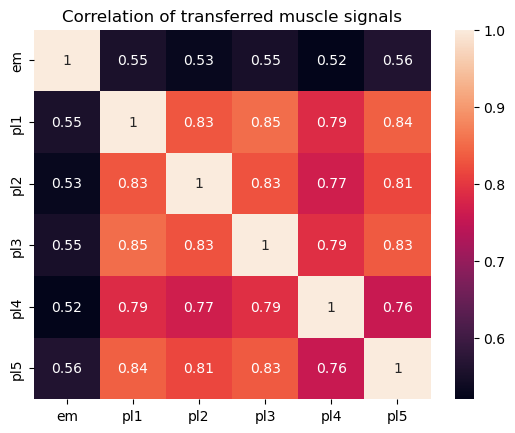

In [6]:
sns.heatmap(muscle_signal.corr(method="spearman"), annot=True)
plt.title("Correlation of transferred muscle signals")